# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.modeling import (
    cargar_datos_clean, remover_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 966 entries, 2007-04-30 to 2026-10-26
Data columns (total 77 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   EURUSD_return                           966 non-null    float64
 1   GBPUSD_return                           966 non-null    float64
 2   USDJPY_return                           966 non-null    float64
 3   USDCAD_return                           966 non-null    float64
 4   USDCHF_return                           966 non-null    float64
 5   AUDUSD_return                           966 non-null    float64
 6   EURUSD_return_lag1                      966 non-null    float64
 7   GBPUSD_return_lag1                      966 non-null    float64
 8   USDJPY_return_lag1                      966 non-null    float64
 9   USDCHF_return_lag1                      966 non-null    float64
 10  AUDUSD_return_lag1                      966

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_pct_diff_sma20_lag1_yeo,966.0,-2.942206e-17,1.000518,-3.458363,-0.620522,0.052545,0.638310,5.473446
Gold_Volume_pct_diff_sma20_lag1_yeo,966.0,5.884412e-17,1.000518,-0.953149,-0.880956,-0.673950,0.900598,2.177346
SPY_Volume_pct_diff_sma20_lag1_yeo,966.0,-1.287215e-17,1.000518,-3.444621,-0.634820,-0.011480,0.662386,3.110249


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_return                             3.252465
VIX_level                                 2.357147
USDCAD_var20_lag1_log                     2.009750
USDCAD_max20_pct_diff_Close_lag1_log1p    1.873639
EURUSD_max20_pct_diff_Close_lag1_log1p    1.435362
GBPUSD_High_Low_spread_lag1_log           1.385097
GBPUSD_max20_pct_diff_Close_lag1_log1p    1.337384
USDCHF_max20_pct_diff_Close_lag1_log1p    1.309802
USDJPY_High_Low_spread_lag1_log           1.238853
USDJPY_max20_pct_diff_Close_lag1_log1p    1.157586
AUDUSD_max20_pct_diff_Close_lag1_log1p    1.118385
USDCHF_var20_lag1_log                     1.076973
EURUSD_High_Low_spread_lag1_log           0.869654
Oil_var20_lag1_log                        0.792974
USDJPY_Open_pct_diff_last_Close_yeo       0.749141
USDCHF_High_Low_spread_lag1_log           0.681390
USDJPY_High_pct_diff_Close_lag1_yeo       0.648846
GBPUSD_var20_lag1_log                     0.617374
AUDUSD_sma20_pct_diff_sma50_lag1          0.589690
Gold_Volume_pct_diff_sma20_lag1

In [5]:
# Asimetria por grupo
cadena = "Open_pct_diff_last_Close"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_Open_pct_diff_last_Close_yeo    0.749141
SPY_Open_pct_diff_last_Close_yeo       0.476628
Oil_Open_pct_diff_last_Close_yeo       0.375426
EURUSD_Open_pct_diff_last_Close_yeo    0.086600
USDCHF_Open_pct_diff_last_Close_yeo   -0.037165
Gold_Open_pct_diff_last_Close_yeo     -0.046636
GBPUSD_Open_pct_diff_last_Close_yeo   -0.310908
USDCAD_Open_pct_diff_last_Close_yeo   -0.622684
AUDUSD_Open_pct_diff_last_Close_yeo   -0.848923


Cont


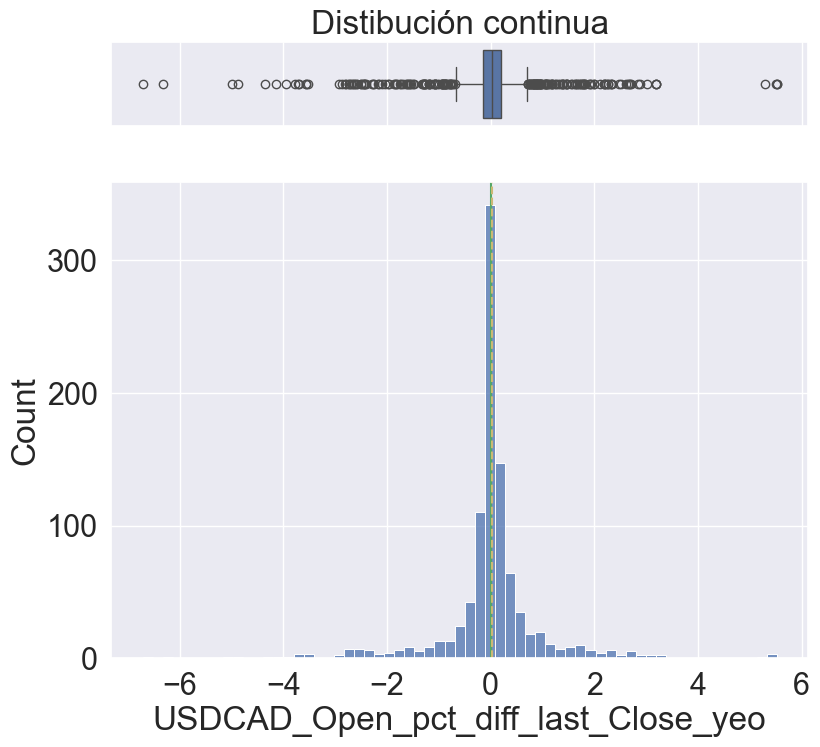

In [6]:
# Visualizar columna
col = 'USDCAD_Open_pct_diff_last_Close_yeo'
pintar_columna(df_clean[col])

In [7]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
249,AUDUSD_sma20_pct_diff_sma50_lag1,USDCAD_sma20_pct_diff_sma50_lag1,0.834000
202,USDCHF_sma20_pct_diff_sma50_lag1,EURUSD_sma20_pct_diff_sma50_lag1,0.785321
1282,GBPUSD_High_pct_diff_Close_lag1_yeo,GBPUSD_return_lag1,0.768430
1139,USDCHF_max20_pct_diff_Close_lag1_log1p,EURUSD_min20_pct_diff_Close_lag1,0.758461
1334,USDJPY_High_pct_diff_Close_lag1_yeo,USDJPY_return_lag1,0.751160
776,USDCHF_var20_lag1_log,EURUSD_var20_lag1_log,0.750077
1820,USDCHF_Low_pct_diff_Close_lag1_yeo,EURUSD_High_pct_diff_Close_lag1_yeo,0.749648
1594,EURUSD_Low_pct_diff_Close_lag1_yeo,USDCHF_High_pct_diff_Close_lag1_yeo,0.742987
1546,EURUSD_Low_pct_diff_Close_lag1_yeo,EURUSD_return_lag1,0.717256
1231,EURUSD_High_pct_diff_Close_lag1_yeo,EURUSD_return_lag1,0.714140


## Analisis de labels

In [8]:
simbolo_objetivo = 'EURUSD'
# Cargar fichero de precios
df = cargar_datos_clean()
df = remover_pares_restantes(df,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df.index.max()
df_train, df_live = separar_datos_live(df=df, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles
objetivo = f"{simbolo_objetivo}_return"
objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004678
1          2     -0.004678      0.004655
2          3      0.004655      0.044001


In [9]:
df_train[objetivo_cat].value_counts()

EURUSD_return_cat
1    322
3    322
2    321
Name: count, dtype: int64

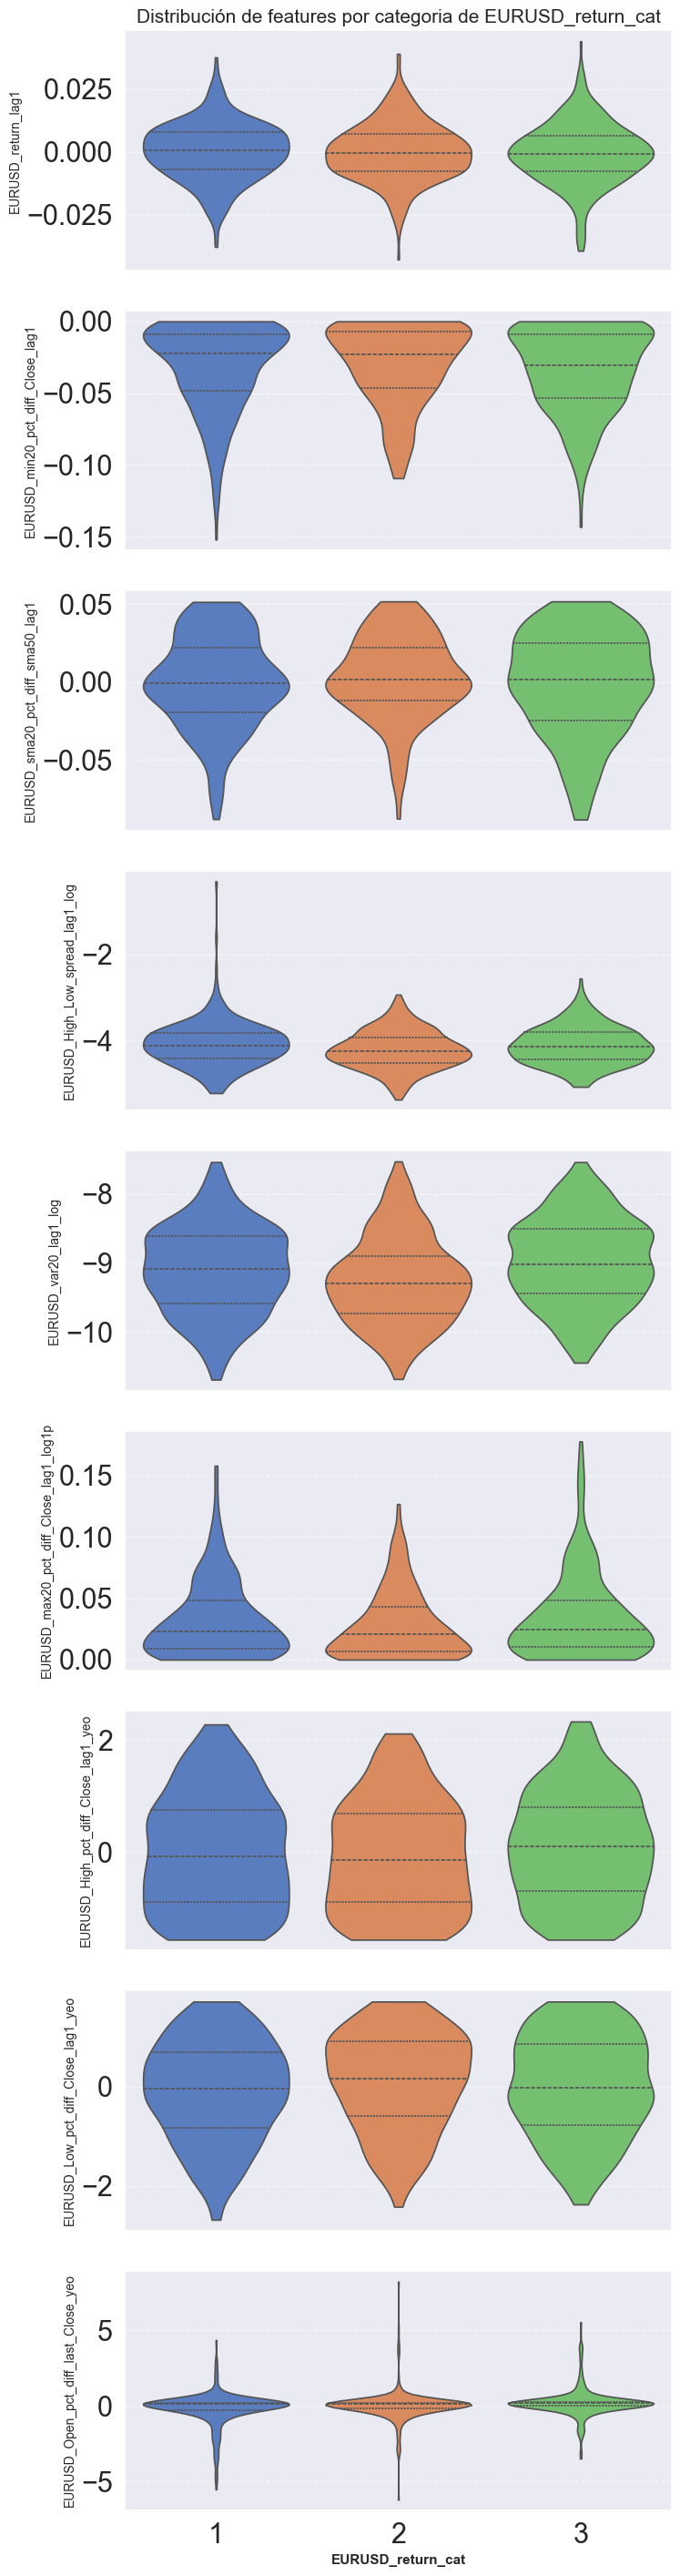

In [10]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)